# 🫀 Low-Lead ECG Screening
### Evaluating diagnostic accuracy retention with wearable-style reduced-lead signals using machine learning

**Course:** Applications and Use Cases of Machine Learning (TE7483) · AIML Department · SIT Pune

---

**The question.** Hospitals record a **12-lead** ECG. Wearables record far fewer leads: a smartwatch records
**1 lead**, handheld devices **6**, chest patches **1-3**. How much diagnostic accuracy do we keep when we only
have the leads a wearable can record, and what happens when the signal is noisy like a real wearable?

**What this notebook does, step by step**

| Step | What happens |
|---|---|
| 1 | Setup and project settings |
| 2 | Download the PTB-XL dataset (21,799 clinical ECGs) |
| 3 | Build the labels (5 heart-condition superclasses) and explore the data |
| 4 | Look at one ECG and the four lead configurations |
| 5 | Preprocess signals and detect heartbeats |
| 6 | Engineer 48 interpretable features per lead |
| 7 | Simulate wearable noise |
| 8 | Extract features for every ECG |
| 9 | Train 3 models × 4 lead configurations, with probability calibration |
| 10 | Evaluate: AUROC, F1, calibration, confidence intervals, significance tests |
| 11 | Robustness to wearable noise |
| 12 | Explain the models with SHAP |
| 13 | Save models for the Streamlit app, then generate the report and slides |

> ⚠️ This is a **screening-support prototype, not a diagnostic tool.**

## 1. Setup

Install the requirements once from a terminal in the project folder:
```
pip install -r requirements-train.txt
```
Then run this notebook from top to bottom (**Run All**). The first run downloads about 1.7 GB and takes
roughly 30-90 minutes; features are cached, so later runs are much faster.

In [ ]:
%pip install --default-timeout=120 -r requirements-train.txt

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# ---------- Standard library ----------
import ast            # turns the text "{'NORM': 100.0}" into a real Python dict
import json
import time
import warnings
import zipfile
from pathlib import Path

# ---------- Data handling ----------
import numpy as np
import pandas as pd

# ---------- Signal processing ----------
from scipy.signal import butter, find_peaks, sosfiltfilt, welch
from scipy.stats import kurtosis, skew

# ---------- Machine learning ----------
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score,
                             roc_auc_score, roc_curve)
from sklearn.calibration import calibration_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier

# ---------- Plotting ----------
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")          # keep the notebook output readable
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e7eb", "axes.axisbelow": True})
print("Libraries loaded.")

Libraries loaded.


### Project settings
Every setting of the experiment is in this one cell, so the whole study can be changed from here.

In [ ]:
# ---------- Folders ----------
PROJECT_DIR = Path.cwd()                       # run the notebook from the project folder
DATA_DIR    = PROJECT_DIR / "data" / "ptbxl"   # PTB-XL is downloaded here (not pushed to GitHub)
FEATURE_DIR = PROJECT_DIR / "data" / "features"
RESULTS_DIR = PROJECT_DIR / "results"
FIG_DIR     = RESULTS_DIR / "figures"
MODEL_DIR   = PROJECT_DIR / "models"           # models used by the Streamlit app
SAMPLE_DIR  = PROJECT_DIR / "app_samples"      # example ECGs shown in the app
for folder in [DATA_DIR, FEATURE_DIR, FIG_DIR, MODEL_DIR, SAMPLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ---------- Run options ----------
USE_SYNTHETIC_DATA = False   # True = quick 3-minute test on fake ECGs (NOT for submission)
FAST_MODE          = False   # True = fewer trees and bootstrap rounds (quick check)

# ---------- Signal ----------
FS = 100                     # sampling rate in Hz (PTB-XL 100 Hz version: 10 s = 1000 samples)
ALL_LEADS = ["I", "II", "III", "AVR", "AVL", "AVF", "V1", "V2", "V3", "V4", "V5", "V6"]

# ---------- The four device scenarios we compare ----------
LEAD_SETS = {
    "12-lead": ALL_LEADS,                                 # hospital ECG
    "6-lead":  ["I", "II", "III", "AVR", "AVL", "AVF"],   # handheld device (limb leads only)
    "3-lead":  ["I", "II", "V2"],                         # chest patch
    "1-lead":  ["I"],                                     # smartwatch (wrist to finger)
}
LEAD_SET_NAMES = list(LEAD_SETS)

# ---------- The five diagnostic superclasses (multi-label targets) ----------
CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
CLASS_NAMES = {"NORM": "Normal ECG", "MI": "Myocardial infarction", "STTC": "ST/T change",
               "CD": "Conduction disturbance", "HYP": "Hypertrophy"}

# ---------- Official PTB-XL patient-wise folds ----------
TRAIN_FOLDS, VAL_FOLD, TEST_FOLD = list(range(1, 9)), 9, 10

# ---------- Wearable noise levels (signal-to-noise ratio in dB) ----------
NOISE_LEVELS = ["clean", 24, 12, 6]      # 24 dB = good contact ... 6 dB = very noisy

# ---------- Models ----------
MODEL_NAMES  = ["LogReg", "RandomForest", "LightGBM"]
APP_MODEL    = "LightGBM"                 # the model shipped in the Streamlit app
N_BOOTSTRAP  = 100 if FAST_MODE else 500  # resamples for confidence intervals
RANDOM_STATE = 42

# ---------- Colours used in all figures ----------
MODEL_COLORS = {"LogReg": "#8e9aaf", "RandomForest": "#3d8b7d", "LightGBM": "#c0392b"}
LEADSET_COLORS = {"12-lead": "#14365d", "6-lead": "#2f6fa6", "3-lead": "#6aa6d6", "1-lead": "#e67e22"}
CLASS_COLORS = {"NORM": "#3d8b7d", "MI": "#c0392b", "STTC": "#e67e22", "CD": "#6c5ce7", "HYP": "#2f6fa6"}

START_TIME = time.time()


def save_figure(fig, name):
    """Save a figure in results/figures (used by the report, slides and app)."""
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()


print("Settings ready. Lead configurations:", LEAD_SET_NAMES)

Settings ready. Lead configurations: ['12-lead', '6-lead', '3-lead', '1-lead']


## 2. Download the PTB-XL dataset

**PTB-XL** (Wagner et al., *Scientific Data*, 2020) is a free dataset on PhysioNet (licence CC BY 4.0):
21,799 ten-second 12-lead ECGs from 18,869 patients, labelled by cardiologists.

The cell below downloads the zip once (~1.7 GB) and extracts only what we need: the two metadata CSV files and
the 100 Hz recordings.

**If the download is slow**, stop the cell and get the files another way, then re-run this cell. It finds
`ptbxl_database.csv` anywhere inside `data/ptbxl/`:
* **AWS mirror (fast, only the files we need):** in a terminal in the project folder run
  `pip install awscli` and then
  `aws s3 sync --no-sign-request s3://physionet-open/ptb-xl/1.0.3/ data/ptbxl/ --exclude "records500/*"`
* **Browser:** download the zip from https://physionet.org/content/ptb-xl/1.0.3/ and extract it into `data/ptbxl/`.

In [ ]:
PTBXL_URL = ("https://physionet.org/static/published-projects/ptb-xl/"
             "ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip")


def find_dataset_root(base):
    """Return the folder that contains ptbxl_database.csv (wherever it was extracted)."""
    matches = list(Path(base).rglob("ptbxl_database.csv"))
    return matches[0].parent if matches else None


def download_ptbxl(dest=DATA_DIR):
    """Download PTB-XL from PhysioNet (only if it is not already on disk)."""
    import requests
    from tqdm.auto import tqdm

    if find_dataset_root(dest):
        print("PTB-XL already downloaded.")
        return find_dataset_root(dest)

    zip_path = dest / "ptbxl.zip"
    if zip_path.exists() and not zipfile.is_zipfile(zip_path):
        print("Found an incomplete ptbxl.zip from an interrupted download - deleting it.")
        zip_path.unlink()

    if not zip_path.exists():
        print("Downloading PTB-XL (~1.7 GB). This happens only once ...")
        print("If the speed is very slow, stop this cell and see README: 'Faster ways to get PTB-XL'.")
        part_path = dest / "ptbxl.zip.part"            # renamed to .zip only when complete
        with requests.get(PTBXL_URL, stream=True, timeout=60) as response:
            response.raise_for_status()
            total = int(response.headers.get("content-length", 0))
            with open(part_path, "wb") as f, tqdm(total=total, unit="B", unit_scale=True) as bar:
                for chunk in response.iter_content(chunk_size=1 << 20):
                    f.write(chunk)
                    bar.update(len(chunk))
        part_path.replace(zip_path)

    print("Extracting metadata and the 100 Hz recordings ...")
    with zipfile.ZipFile(zip_path) as z:
        wanted = [m for m in z.namelist() if m.endswith(".csv") or "/records100/" in m]
        for member in tqdm(wanted):
            z.extract(member, dest)
    return find_dataset_root(dest)


if USE_SYNTHETIC_DATA:
    # Fake ECGs in the exact PTB-XL format, for a quick test only.
    # Create them first with:  python scripts/make_synthetic_ptbxl.py --n 2000
    DATASET_ROOT = find_dataset_root(PROJECT_DIR / "data" / "synthetic_ptbxl")
    assert DATASET_ROOT, "Run: python scripts/make_synthetic_ptbxl.py --n 2000"
else:
    DATASET_ROOT = download_ptbxl()

IS_SYNTHETIC = (DATASET_ROOT / "SYNTHETIC_DATA.txt").exists()
print("Dataset folder:", DATASET_ROOT)
if IS_SYNTHETIC:
    print("⚠️  Using SYNTHETIC test data - results are NOT real and must not be submitted.")

PTB-XL already downloaded.
Dataset folder: c:\Users\Kashish\Downloads\lowlead-ecg-screening\lowlead-ecg-screening\data\ptbxl


## 3. Build the labels and explore the data

Each ECG has a set of **SCP-ECG statements** (e.g. `IMI` = inferior myocardial infarction). The file
`scp_statements.csv` maps every *diagnostic* statement to one of five **superclasses**.

One ECG can have several superclasses at once (e.g. MI *and* a conduction disturbance), so this is a
**multi-label** problem: the target is a 5-element vector of 0/1 values.

In [ ]:
# Read the metadata: one row per ECG
meta = pd.read_csv(DATASET_ROOT / "ptbxl_database.csv", index_col="ecg_id")
meta["scp_codes"] = meta["scp_codes"].apply(ast.literal_eval)     # text -> dict
n_records_raw = len(meta)

# Map each diagnostic SCP code to its superclass, e.g. "IMI" -> "MI"
statements = pd.read_csv(DATASET_ROOT / "scp_statements.csv", index_col=0)
code_to_class = statements[statements["diagnostic"] == 1]["diagnostic_class"].to_dict()


def get_superclasses(scp_codes):
    """All superclasses that appear among an ECG's diagnostic statements."""
    return sorted({code_to_class[code] for code in scp_codes if code in code_to_class})


meta["superclasses"] = meta["scp_codes"].apply(get_superclasses)

# Drop ECGs that have no diagnostic superclass (as in the official benchmark)
meta = meta[meta["superclasses"].map(len) > 0].copy()
n_dropped = n_records_raw - len(meta)

# One 0/1 column per class = the multi-label target
for c in CLASSES:
    meta[c] = meta["superclasses"].apply(lambda labels: int(c in labels))

print(f"ECGs in file: {n_records_raw:,} | without a diagnostic label (dropped): {n_dropped:,} | "
      f"used: {len(meta):,} | patients: {meta['patient_id'].nunique():,}")
meta[["age", "sex", "superclasses", "strat_fold"] + CLASSES].head()

ECGs in file: 21,799 | without a diagnostic label (dropped): 411 | used: 21,388 | patients: 18,617


,age,sex,superclasses,strat_fold,NORM,MI,STTC,CD,HYP
ecg_id,,,,,,,,,
1,56.0,1,[NORM],3,1,0,0,0,0
2,19.0,0,[NORM],2,1,0,0,0,0
3,37.0,1,[NORM],5,1,0,0,0,0
4,24.0,0,[NORM],3,1,0,0,0,0
5,19.0,1,[NORM],4,1,0,0,0,0


### 3.1 Class balance and multi-label structure

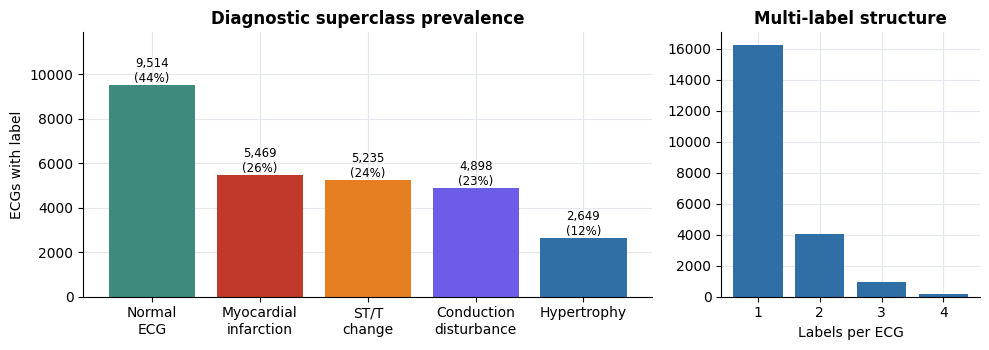

24.1% of ECGs have more than one label.


In [ ]:
class_counts = meta[CLASSES].sum()
labels_per_ecg = meta[CLASSES].sum(axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
bars = ax1.bar([CLASS_NAMES[c].replace(" ", "\n", 1) for c in CLASSES], class_counts,
               color=[CLASS_COLORS[c] for c in CLASSES])
for bar, count in zip(bars, class_counts):
    ax1.text(bar.get_x() + bar.get_width() / 2, count, f"{count:,}\n({count / len(meta):.0%})",
             ha="center", va="bottom", fontsize=8.5)
ax1.set_ylim(0, class_counts.max() * 1.25)
ax1.set_title("Diagnostic superclass prevalence", fontweight="bold")
ax1.set_ylabel("ECGs with label")

counts = labels_per_ecg.value_counts().sort_index()
ax2.bar(counts.index.astype(str), counts.values, color="#2f6fa6")
ax2.set_title("Multi-label structure", fontweight="bold")
ax2.set_xlabel("Labels per ECG")
fig.tight_layout()
save_figure(fig, "01_class_distribution.png")

print(f"{(labels_per_ecg > 1).mean():.1%} of ECGs have more than one label.")

### 3.2 Attributes, data types and missing values

In [ ]:
overview = pd.DataFrame({
    "data type": meta[["age", "sex", "height", "weight", "strat_fold"]].dtypes.astype(str),
    "missing %": meta[["age", "sex", "height", "weight", "strat_fold"]].isna().mean().mul(100).round(1),
})
print(f"Age: {meta['age'].mean():.1f} ± {meta['age'].std():.1f} years | "
      f"male: {(meta['sex'] == 0).mean():.1%}")
print("Height and weight are mostly missing, so we do not use them. We also leave out age and sex so the model")
print("is a pure signal-based screener. The ECG signals themselves have no missing values.")
overview

Age: 62.6 ± 32.2 years | male: 51.9%
Height and weight are mostly missing, so we do not use them. We also leave out age and sex so the model
is a pure signal-based screener. The ECG signals themselves have no missing values.


,data type,missing %
age,float64,0.0
sex,int64,0.0
height,float64,67.7
weight,float64,56.2
strat_fold,int64,0.0


### 3.3 Train / validation / test split

PTB-XL provides 10 **patient-wise, label-stratified** folds: one patient never appears in two folds
(no leakage) and class proportions are similar in every fold. We use the official split:

* **Folds 1-8 → training** the models
* **Fold 9 → validation**: probability calibration and choosing decision thresholds
* **Fold 10 → test**: used once, for the final results

In [ ]:
train_ids = meta.index[meta["strat_fold"].isin(TRAIN_FOLDS)]
val_ids   = meta.index[meta["strat_fold"] == VAL_FOLD]
test_ids  = meta.index[meta["strat_fold"] == TEST_FOLD]

split_table = pd.DataFrame({
    name: {"ECGs": len(ids), **{c: f"{meta.loc[ids, c].mean():.1%}" for c in CLASSES}}
    for name, ids in [("train", train_ids), ("val", val_ids), ("test", test_ids)]
}).T
split_table

,ECGs,NORM,MI,STTC,CD,HYP
train,17084,44.5%,25.6%,24.5%,22.9%,12.4%
val,2146,44.5%,25.2%,24.6%,23.1%,12.5%
test,2158,44.6%,25.5%,24.1%,23.0%,12.1%


## 4. Look at one ECG and the four lead configurations

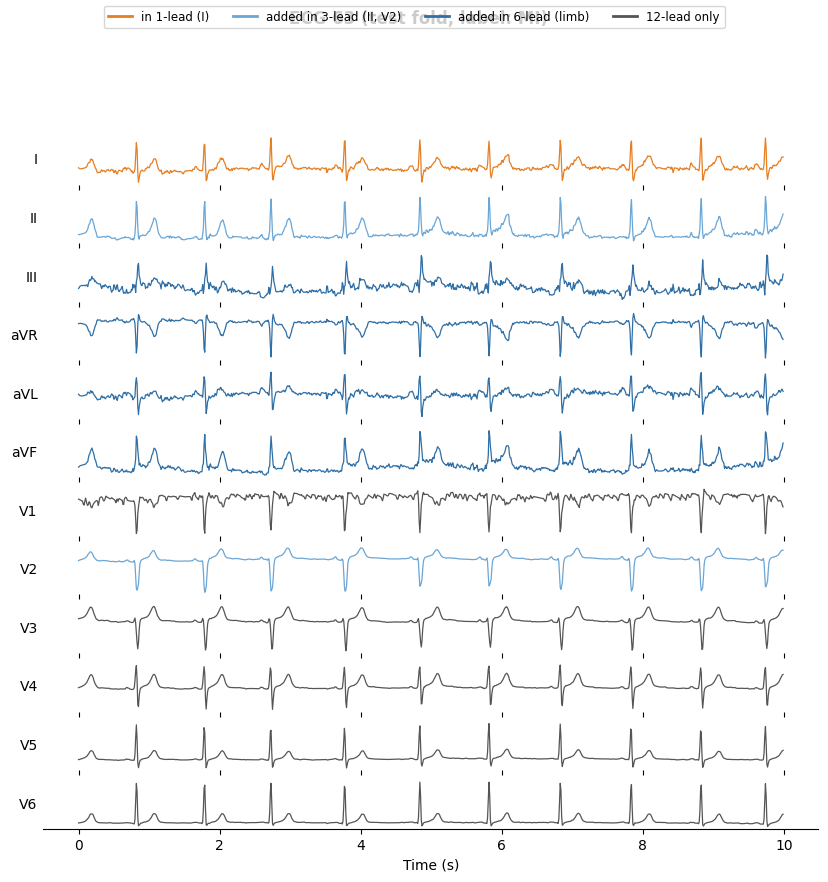

In [ ]:
def read_ecg(filename):
    """Read one 100 Hz recording -> array of shape (1000 samples, 12 leads) in millivolts."""
    import wfdb
    signal, info = wfdb.rdsamp(str(DATASET_ROOT / filename))
    lead_order = [name.upper() for name in info["sig_name"]]
    return signal[:, [lead_order.index(lead) for lead in ALL_LEADS]].astype(np.float32)


# Pick the first test ECG with myocardial infarction as our running example
example_id = meta.loc[test_ids][meta.loc[test_ids, "MI"] == 1].index[0]
example = read_ecg(meta.loc[example_id, "filename_lr"])
time_axis = np.arange(len(example)) / FS


def smallest_set_with(lead):
    """The smallest lead configuration that still contains this lead (for colouring)."""
    for name in reversed(LEAD_SET_NAMES):
        if lead in LEAD_SETS[name]:
            return name


fig, axes = plt.subplots(12, 1, figsize=(10, 9), sharex=True)
for i, (ax, lead) in enumerate(zip(axes, ALL_LEADS)):
    group = smallest_set_with(lead)
    ax.plot(time_axis, example[:, i], lw=0.9, color="#555" if group == "12-lead" else LEADSET_COLORS[group])
    ax.set_ylabel(lead.replace("AV", "aV"), rotation=0, ha="right", va="center")
    ax.set_yticks([]); ax.grid(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_visible(side == "bottom" and i == 11)
axes[-1].set_xlabel("Time (s)")
legend = [plt.Line2D([], [], color=LEADSET_COLORS["1-lead"], lw=2, label="in 1-lead (I)"),
          plt.Line2D([], [], color=LEADSET_COLORS["3-lead"], lw=2, label="added in 3-lead (II, V2)"),
          plt.Line2D([], [], color=LEADSET_COLORS["6-lead"], lw=2, label="added in 6-lead (limb)"),
          plt.Line2D([], [], color="#555", lw=2, label="12-lead only")]
fig.legend(handles=legend, loc="upper center", ncol=4, fontsize=8.5)
fig.suptitle(f"ECG {example_id} (test fold, label: {', '.join(meta.loc[example_id, 'superclasses'])})",
             y=1.02, fontweight="bold")
save_figure(fig, "02_example_ecg_leadsets.png")

## 5. Preprocessing and heartbeat (R-peak) detection

1. **Band-pass filter 0.5-40 Hz.** Below 0.5 Hz is slow drift from breathing (baseline wander); above 40 Hz is
   mostly muscle noise. The heart's waves (P, QRS, T) are in between. `sosfiltfilt` filters forwards and
   backwards, so the waves are not shifted in time.
2. **R-peak detection.** The QRS complex is the steepest part of a heartbeat, so we square the signal's slope
   (derivative), smooth it over 100 ms and find peaks above an adaptive threshold, at least 300 ms apart.
   Using the *absolute* deflection means it also works in leads where the QRS points downwards (aVR, V1).

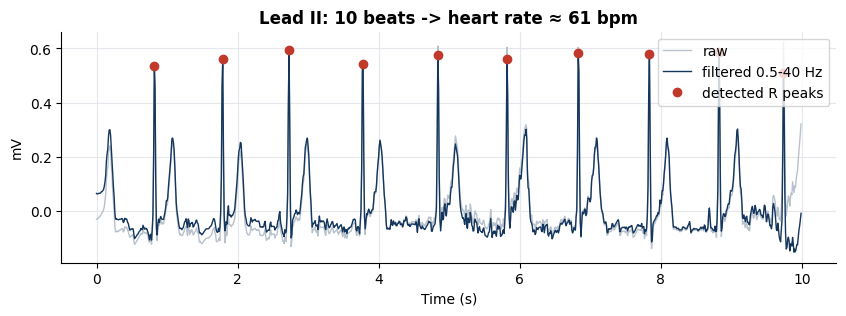

In [ ]:
BANDPASS_FILTER = butter(3, [0.5, 40.0], btype="band", fs=FS, output="sos")


def bandpass(x):
    """Remove baseline wander (<0.5 Hz) and high-frequency noise (>40 Hz)."""
    return sosfiltfilt(BANDPASS_FILTER, x, axis=0)


def detect_r_peaks(x):
    """Return the sample index of every R peak in a filtered single-lead signal."""
    slope_energy = np.diff(x, prepend=x[0]) ** 2                       # steep slopes -> large values
    window = int(0.1 * FS)                                             # 100 ms smoothing window
    envelope = np.convolve(slope_energy, np.ones(window) / window, mode="same")
    if envelope.max() <= 0:
        return np.array([], dtype=int)
    threshold = 0.3 * np.percentile(envelope, 99)                      # adapts to each signal
    candidates, _ = find_peaks(envelope, height=threshold, distance=int(0.3 * FS))

    # Move each candidate to the largest deflection within ±80 ms (the true R peak)
    centred, w = x - np.median(x), int(0.08 * FS)
    peaks = [max(0, c - w) + int(np.argmax(np.abs(centred[max(0, c - w):c + w + 1]))) for c in candidates]
    peaks = np.unique(peaks)
    if len(peaks) > 1:                                                 # remove duplicates < 250 ms apart
        peaks = peaks[np.insert(np.diff(peaks) > int(0.25 * FS), 0, True)]
    return peaks


# Show it on lead II of the example ECG
raw_lead_ii = example[:, 1]
filtered_lead_ii = bandpass(raw_lead_ii)
r_peaks = detect_r_peaks(filtered_lead_ii)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(time_axis, raw_lead_ii, color="#b8c2cc", lw=1, label="raw")
ax.plot(time_axis, filtered_lead_ii, color="#14365d", lw=1, label="filtered 0.5-40 Hz")
ax.plot(r_peaks / FS, filtered_lead_ii[r_peaks], "o", color="#c0392b", label="detected R peaks")
ax.set_xlabel("Time (s)"); ax.set_ylabel("mV"); ax.legend(loc="upper right")
ax.set_title(f"Lead II: {len(r_peaks)} beats -> heart rate ≈ {60 * FS / np.mean(np.diff(r_peaks)):.0f} bpm",
             fontweight="bold")
plt.show()

## 6. Feature engineering (48 features per lead)

Instead of feeding raw samples to a black box, we compute **features a cardiologist would recognise**. Every
feature is computed per lead and named `LEAD__feature` (e.g. `V2__st_level`). A reduced-lead model then simply
uses the columns of its own leads, so all four configurations share exactly the same feature extraction.

| Group | Features | What it captures |
|---|---|---|
| Rhythm (7) | beat count, heart rate, RR std, RR CV, RMSSD, pNN50, RR range | rate and regularity |
| Amplitude statistics (8) | std, peak-to-peak, skew, kurtosis, 5th/95th percentile, mean abs, zero-crossings | overall voltage |
| Spectral (5) | power in 0.5-5 / 5-15 / 15-45 Hz, spectral entropy, peak frequency | energy distribution |
| Morphology (14) | P, Q, R, S, QRS amplitude/area/width, ST level/slope, T amplitude/max/min/area, beat consistency | the waves |
| Beat shape (14) | the median heartbeat averaged into 14 bins | overall waveform shape |

The **median beat** is built by cutting every heartbeat from 250 ms before to 450 ms after its R peak and taking
the median at every time point. This cancels noise and one-off irregular beats.

In [ ]:
BEFORE_R, AFTER_R = 25, 45          # median-beat window in samples: 250 ms before, 450 ms after the R peak
N_SHAPE_BINS = 14


def rhythm_features(peaks):
    """Heart rate and heart-rate variability from the RR intervals (time between beats)."""
    f = {"n_beats": float(len(peaks))}
    if len(peaks) < 3:                                     # not enough beats -> missing values
        return {**f, "hr": np.nan, "rr_std": np.nan, "rr_cv": np.nan, "rmssd": np.nan,
                "pnn50": np.nan, "rr_range": np.nan}
    rr = np.diff(peaks) / FS * 1000.0                      # RR intervals in ms
    rr_change = np.diff(rr)
    return {**f,
            "hr": 60000.0 / np.mean(rr),                   # beats per minute
            "rr_std": np.std(rr),
            "rr_cv": np.std(rr) / np.mean(rr),
            "rmssd": np.sqrt(np.mean(rr_change ** 2)) if len(rr_change) else np.nan,
            "pnn50": np.mean(np.abs(rr_change) > 50) if len(rr_change) else np.nan,
            "rr_range": rr.max() - rr.min()}


def amplitude_features(x):
    """Statistics of the filtered signal's voltage distribution."""
    return {"std": np.std(x), "ptp": np.ptp(x), "skew": float(skew(x)), "kurt": float(kurtosis(x)),
            "p05": np.percentile(x, 5), "p95": np.percentile(x, 95), "abs_mean": np.mean(np.abs(x)),
            "zcr": np.mean(np.abs(np.diff(np.sign(x - np.mean(x)))) > 0)}


def spectral_features(x):
    """How the signal's energy is spread over frequencies (Welch power spectrum)."""
    freqs, power = welch(x, fs=FS, nperseg=min(256, len(x)))
    total = power[(freqs >= 0.5) & (freqs <= 45)].sum() + 1e-12
    share = power / (power.sum() + 1e-12)
    return {"bp_low": power[(freqs >= 0.5) & (freqs < 5)].sum() / total,
            "bp_mid": power[(freqs >= 5) & (freqs < 15)].sum() / total,
            "bp_high": power[(freqs >= 15) & (freqs < 45)].sum() / total,
            "spec_entropy": float(-(share * np.log(share + 1e-12)).sum()),
            "peak_freq": float(freqs[np.argmax(power)])}


MORPHOLOGY_NAMES = ["p_amp", "q_amp", "r_amp", "s_amp", "qrs_ptp", "qrs_area", "qrs_width", "st_level",
                    "st_slope", "t_amp", "t_max", "t_min", "t_area", "beat_corr"]


def morphology_features(x, peaks):
    """Measure the P, QRS, ST and T waves on the median heartbeat."""
    missing = {**{k: np.nan for k in MORPHOLOGY_NAMES}, **{f"tmpl_{i}": np.nan for i in range(N_SHAPE_BINS)}}
    peaks = peaks[(peaks >= BEFORE_R) & (peaks + AFTER_R <= len(x))]   # beats fully inside the recording
    if len(peaks) < 2:
        return missing

    beats = np.stack([x[p - BEFORE_R:p + AFTER_R] for p in peaks])     # one row per heartbeat
    beat = np.median(beats, axis=0)                                    # the median heartbeat
    beat = beat - np.median(beat[BEFORE_R - 12:BEFORE_R - 5])          # baseline = flat PR segment
    r = BEFORE_R                                                       # index of the R peak

    # QRS width: where the slope is steep (>15% of the steepest slope) around the R peak
    slope = np.abs(np.diff(beat[r - 15:r + 16]))
    steep = np.where(slope > 0.15 * slope.max())[0] if slope.max() > 0 else np.array([])
    t_wave = beat[r + 15:r + 40]                                       # 150-400 ms after R
    p_wave = beat[r - 25:r - 10]                                       # 250-100 ms before R
    correlations = [np.corrcoef(b, beat)[0, 1] for b in beats if np.std(b) > 0]

    f = {"p_amp": p_wave[np.argmax(np.abs(p_wave))],
         "q_amp": beat[r - 8:r].min(),                                 # dip just before R
         "r_amp": beat[r],
         "s_amp": beat[r:r + 8].min(),                                 # dip just after R
         "qrs_ptp": np.ptp(beat[r - 8:r + 9]),
         "qrs_area": np.abs(beat[r - 6:r + 7]).sum() / FS,
         "qrs_width": (steep[-1] - steep[0] + 1) / FS * 1000 if len(steep) else np.nan,   # ms
         "st_level": beat[r + 9:r + 13].mean(),                        # 90-120 ms after R
         "st_slope": beat[r + 14] - beat[r + 8],
         "t_amp": t_wave[np.argmax(np.abs(t_wave))],                   # signed: negative = inverted T
         "t_max": t_wave.max(), "t_min": t_wave.min(), "t_area": t_wave.sum() / FS,
         "beat_corr": float(np.nanmean(correlations)) if correlations else np.nan}
    shape = {f"tmpl_{i}": float(part.mean()) for i, part in enumerate(np.array_split(beat, N_SHAPE_BINS))}
    return {**f, **shape}


def lead_features(raw_lead):
    """All 48 features of one lead."""
    x = bandpass(raw_lead)
    peaks = detect_r_peaks(x)
    return {**rhythm_features(peaks), **amplitude_features(x), **spectral_features(x),
            **morphology_features(x, peaks)}


def ecg_features(signal, leads=ALL_LEADS):
    """Features of a whole ECG as one flat dict: {'I__hr': ..., 'V2__st_level': ..., ...}."""
    features = {}
    for i, lead in enumerate(leads):
        for name, value in lead_features(signal[:, i]).items():
            features[f"{lead}__{name}"] = float(value)
    return features


example_features = ecg_features(example)
FEATURES_PER_LEAD = len(example_features) // len(ALL_LEADS)
print(f"{FEATURES_PER_LEAD} features per lead, {len(example_features)} for 12 leads.")
pd.Series({k: v for k, v in example_features.items() if k.startswith("II__")}).round(3).to_frame("lead II")

48 features per lead, 576 for 12 leads.


,lead II
II__n_beats,10.000
II__hr,60.538
II__rr_std,45.569
II__rr_cv,0.046
II__rmssd,58.310
II__pnn50,0.375
II__rr_range,150.000
II__std,0.115
II__ptp,0.748
II__skew,2.435


**Consistency check with the app.** The Streamlit app computes features with its own copy of these functions
in `src/features.py` (so the app does not need this notebook). This check makes sure both give identical numbers.

In [ ]:
from src.features import record_features as app_features

app_version = app_features(example)
assert app_version.keys() == example_features.keys()
assert np.allclose([app_version[k] for k in app_version], [example_features[k] for k in app_version], equal_nan=True)
print("✓ Notebook features and app features are identical.")

✓ Notebook features and app features are identical.


## 7. Simulating wearable noise

Wearables are recorded while people move, with small dry electrodes. We mix three realistic artefacts:

* **Baseline wander** (45% of the noise power): slow drift from breathing and electrode movement, 0.05-0.5 Hz
* **Muscle (EMG) noise** (35%): fast, random noise from arm and chest muscles, 15-45 Hz
* **Motion artefacts** (20%): a few short, large bumps when the wearer moves

The mix is scaled so that **SNR = 10·log10(signal power / noise power)** equals the target (24, 12 or 6 dB).
Noise is added **only to the test ECGs**: models are trained on clean hospital data and then tested on noisy
data, just as a deployed device would be. Each ECG gets a fixed random seed, so results are reproducible.

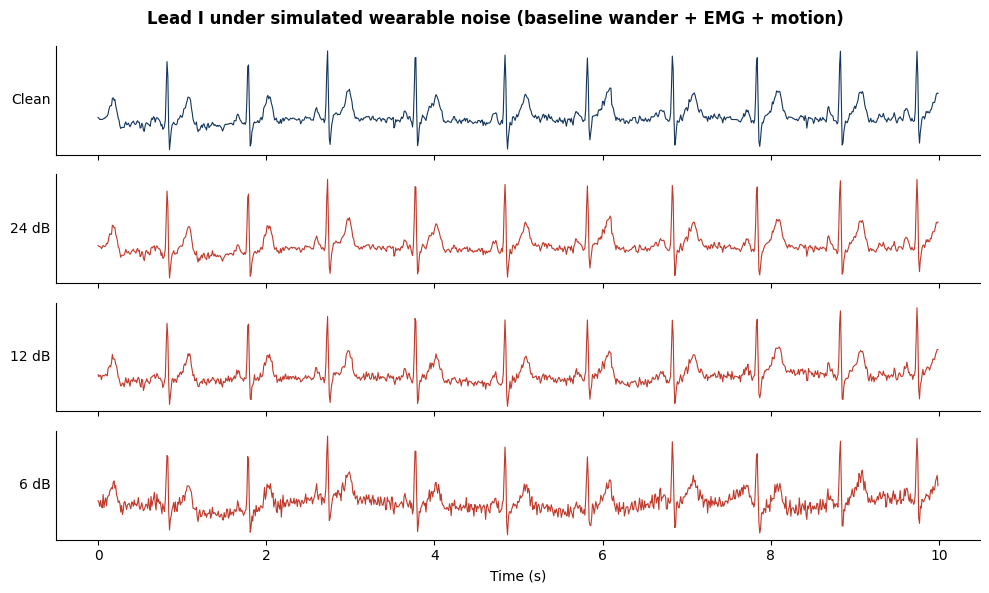

Target SNR 12 dB -> achieved 12.00 dB


In [ ]:
def unit_power(x):
    """Scale a signal so its average power is 1."""
    return x / np.sqrt(np.mean(x ** 2))


def add_wearable_noise(signal, snr_db, seed):
    """Return a noisy copy of an ECG (shape: samples x leads) at the given SNR in dB."""
    rng = np.random.default_rng(seed)
    n_samples, n_leads = signal.shape
    t = np.arange(n_samples) / FS
    emg_filter = butter(4, [15, 0.45 * FS], btype="band", fs=FS, output="sos")
    noisy = signal.astype(np.float64).copy()

    for lead in range(n_leads):
        # 1) baseline wander: three slow sine waves
        baseline = sum(rng.uniform(0.5, 1.0) * np.sin(2 * np.pi * rng.uniform(0.05, 0.5) * t
                                                       + rng.uniform(0, 2 * np.pi)) for _ in range(3))
        # 2) muscle noise: random noise kept between 15 and 45 Hz
        emg = sosfiltfilt(emg_filter, rng.standard_normal(n_samples + 200))[100:-100]
        # 3) motion artefacts: 1-3 smooth bumps at random times
        motion = np.zeros(n_samples)
        for _ in range(rng.integers(1, 4)):
            centre, width = rng.integers(0, n_samples), rng.uniform(0.1, 0.6) * FS
            motion += rng.choice([-1, 1]) * rng.uniform(0.5, 1.0) * np.exp(-0.5 * ((np.arange(n_samples) - centre) / width) ** 2)

        noise = unit_power(np.sqrt(0.45) * unit_power(baseline) + np.sqrt(0.35) * unit_power(emg)
                           + np.sqrt(0.20) * unit_power(motion))
        signal_power = np.mean((signal[:, lead] - signal[:, lead].mean()) ** 2)
        if signal_power > 0:
            noise_power = signal_power / 10 ** (snr_db / 10)          # from the SNR definition
            noisy[:, lead] += noise * np.sqrt(noise_power)
    return noisy.astype(np.float32)


def noise_seed(ecg_id, snr_db):
    return int(ecg_id) * 1000 + int(snr_db)


fig, axes = plt.subplots(len(NOISE_LEVELS), 1, figsize=(10, 6), sharex=True)
for ax, level in zip(axes, NOISE_LEVELS):
    shown = example if level == "clean" else add_wearable_noise(example, level, noise_seed(example_id, level))
    ax.plot(time_axis, shown[:, 0], lw=0.8, color="#14365d" if level == "clean" else "#c0392b")
    ax.set_ylabel("Clean" if level == "clean" else f"{level} dB", rotation=0, ha="right", va="center")
    ax.set_yticks([]); ax.grid(False)
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Lead I under simulated wearable noise (baseline wander + EMG + motion)", fontweight="bold")
fig.tight_layout()
save_figure(fig, "03_noise_examples.png")

# Quick check: the achieved SNR matches the target
check = add_wearable_noise(example, 12, seed=1)
achieved = 10 * np.log10(np.mean((example[:, 0] - example[:, 0].mean()) ** 2) / np.mean((check[:, 0] - example[:, 0]) ** 2))
print(f"Target SNR 12 dB -> achieved {achieved:.2f} dB")

## 8. Extract features for every ECG

This is the slow step (it reads ~21,800 files), so it runs on all CPU cores and the result is **cached** in
`data/features/`. Test ECGs are also processed at every noise level.

In [ ]:
def features_for_one_ecg(ecg_id, filename, noise_levels):
    """Read one ECG and return {noise level: feature dict}."""
    signal = read_ecg(filename)
    result = {}
    for level in noise_levels:
        noisy = signal if level == "clean" else add_wearable_noise(signal, level, noise_seed(ecg_id, level))
        result[level] = ecg_features(noisy)
    return ecg_id, result


cache_files = {level: FEATURE_DIR / f"features_{level}.pkl" for level in NOISE_LEVELS}
cache_ok = all(p.exists() for p in cache_files.values()) and \
    set(pd.read_pickle(cache_files["clean"]).index) == set(meta.index)

if cache_ok:
    features = {level: pd.read_pickle(path) for level, path in cache_files.items()}
    print("Loaded cached features.")
else:
    from joblib import Parallel, delayed
    from tqdm.auto import tqdm

    test_set = set(test_ids)
    jobs = [(ecg_id, row.filename_lr, NOISE_LEVELS if ecg_id in test_set else ["clean"])
            for ecg_id, row in meta.iterrows()]
    print(f"Extracting features from {len(jobs):,} ECGs on all CPU cores ...")
    results = Parallel(n_jobs=-1, batch_size=32)(delayed(features_for_one_ecg)(*job) for job in tqdm(jobs))

    features = {}
    for level in NOISE_LEVELS:
        rows = {ecg_id: per_level[level] for ecg_id, per_level in results if level in per_level}
        features[level] = pd.DataFrame.from_dict(rows, orient="index").sort_index()
        features[level].to_pickle(cache_files[level])

X_all = features["clean"]                           # clean features for every ECG
Y_all = meta[CLASSES]                               # 0/1 labels
missing_share = X_all.isna().mean()
print(f"Feature table: {X_all.shape[0]:,} ECGs × {X_all.shape[1]} features")
print(f"Missing feature values: {missing_share.mean():.2%} overall (max {missing_share.max():.1%} in one feature)."
      " They happen when too few beats are detected and are filled with the training median inside each model.")


def columns_for(lead_set):
    """The feature columns a lead configuration is allowed to use."""
    allowed = set(LEAD_SETS[lead_set])
    return [col for col in X_all.columns if col.split("__")[0] in allowed]


pd.Series({name: len(columns_for(name)) for name in LEAD_SET_NAMES}, name="features").to_frame()

Loaded cached features.
Feature table: 21,388 ECGs × 576 features
Missing feature values: 0.15% overall (max 0.9% in one feature). They happen when too few beats are detected and are filled with the training median inside each model.


,features
12-lead,576
6-lead,288
3-lead,144
1-lead,48


## 9. Models: training, calibration and thresholds

**Three models**, from simple to powerful:

| Model | Why |
|---|---|
| **Logistic Regression** | Linear, transparent baseline. Features are standardised; classes are weighted to handle imbalance. |
| **Random Forest** | Many decision trees on random subsets; captures non-linear patterns and is robust to noise. |
| **LightGBM** | Gradient-boosted trees, usually the strongest model for tabular data; handles missing values itself. |

**Multi-label strategy (one-vs-rest).** For each of the 5 classes we train a separate yes/no model.

**Probability calibration (Platt scaling).** A raw model score of 0.8 does not necessarily mean an 80% chance.
On the validation fold we fit a small logistic regression that maps raw scores to *calibrated* probabilities, so
"30%" really means about 3 in 10 similar ECGs have the condition. A clinic can then choose its own referral cut-off.

**Decision threshold.** For each class we pick the probability cut-off that gives the best F1 score on the
validation fold.

In [ ]:
def make_model(name):
    """Create a fresh, untrained model."""
    if name == "LogReg":
        return Pipeline([("fill_missing", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler()),
                         ("model", LogisticRegression(C=0.05, max_iter=3000, class_weight="balanced"))])
    if name == "RandomForest":
        return Pipeline([("fill_missing", SimpleImputer(strategy="median")),
                         ("model", RandomForestClassifier(n_estimators=100 if FAST_MODE else 300,
                                                          min_samples_leaf=3, max_features="sqrt",
                                                          class_weight="balanced_subsample",
                                                          n_jobs=-1, random_state=RANDOM_STATE))])
    if name == "LightGBM":
        return LGBMClassifier(n_estimators=150 if FAST_MODE else 500, learning_rate=0.03, num_leaves=31,
                              min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                              reg_lambda=1.0, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)


def to_logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


class ECGScreeningModel:
    """One calibrated yes/no model per class, for one model type and one lead configuration."""

    def __init__(self, model_name, lead_set):
        self.model_name, self.lead_set = model_name, lead_set
        self.columns = columns_for(lead_set)
        self.models, self.calibrators, self.thresholds = {}, {}, {}

    def fit(self, X_train, Y_train, X_val, Y_val):
        for c in CLASSES:
            # 1) train on folds 1-8
            model = make_model(self.model_name).fit(X_train[self.columns], Y_train[c])
            # 2) Platt calibration on fold 9: logistic regression on the logit of the raw score
            raw_val = model.predict_proba(X_val[self.columns])[:, 1]
            calibrator = LogisticRegression(C=1e4, max_iter=1000).fit(to_logit(raw_val)[:, None], Y_val[c])
            calibrated_val = calibrator.predict_proba(to_logit(raw_val)[:, None])[:, 1]
            # 3) threshold with the best F1 on fold 9
            grid = np.linspace(0.05, 0.95, 91)
            best = grid[np.argmax([f1_score(Y_val[c], calibrated_val >= t, zero_division=0) for t in grid])]
            self.models[c], self.calibrators[c], self.thresholds[c] = model, calibrator, float(best)
        return self

    def predict_proba(self, X, calibrated=True):
        """Probabilities, shape (n_ECGs, 5)."""
        columns = []
        for c in CLASSES:
            raw = self.models[c].predict_proba(X[self.columns])[:, 1]
            columns.append(self.calibrators[c].predict_proba(to_logit(raw)[:, None])[:, 1] if calibrated else raw)
        return np.column_stack(columns)

### 9.1 Hyperparameter tuning

Every model has settings that are not learned from the data (e.g. how many trees, how fast LightGBM learns).
We choose them by **trying several candidates and keeping the one with the best macro AUROC on the validation
fold (fold 9)**:

* **Logistic Regression:** regularisation strength `C` (small C = simpler model, less overfitting).
* **Random Forest:** minimum samples per leaf (tree depth) and features tried at each split.
* **LightGBM:** learning rate and number of leaves; the **number of trees is found by early stopping**: training
  stops once the validation AUROC has not improved for 100 trees.

The original settings are included as the `default` candidate, so tuning can only keep or improve the
validation score. Tuning uses the **12-lead** features and the chosen settings are reused for every lead
configuration, so all four device scenarios are compared with the same models.

The **test fold (10) is never used here**, so the final test results stay an honest estimate.
This step takes about **10-20 minutes** on a laptop.

In [ ]:
import lightgbm as lgb

# ---------- Tuning data: 12-lead features, train on folds 1-8, score on validation fold 9 ----------
tune_columns = columns_for("12-lead")
X_tune_train, X_tune_val = X_all.loc[train_ids, tune_columns], X_all.loc[val_ids, tune_columns]
Y_tune_train, Y_tune_val = Y_all.loc[train_ids], Y_all.loc[val_ids]

# ---------- The settings used so far ("default") and the candidates to try ----------
DEFAULTS = {"LogReg": {"C": 0.05},
            "RandomForest": {"min_samples_leaf": 3, "max_features": "sqrt"},
            "LightGBM": {"learning_rate": 0.03, "num_leaves": 31, "n_estimators": 150 if FAST_MODE else 500}}
SEARCH_SPACE = {
    "LogReg": [{"C": c} for c in [0.01, 0.2, 1.0]],
    "RandomForest": [{"min_samples_leaf": 1, "max_features": "sqrt"},
                     {"min_samples_leaf": 10, "max_features": "sqrt"},
                     {"min_samples_leaf": 3, "max_features": "log2"}],
    "LightGBM": [{"learning_rate": lr, "num_leaves": leaves} for lr in [0.03, 0.06] for leaves in [15, 31, 63]],
}


def build_model(name, params):
    """Create an untrained model with the given hyperparameters (anything not given keeps its default)."""
    if name == "LogReg":
        return Pipeline([("fill_missing", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler()),
                         ("model", LogisticRegression(C=params.get("C", 0.05), max_iter=3000,
                                                      class_weight="balanced"))])
    if name == "RandomForest":
        return Pipeline([("fill_missing", SimpleImputer(strategy="median")),
                         ("model", RandomForestClassifier(
                             n_estimators=params.get("n_estimators", 100 if FAST_MODE else 300),
                             min_samples_leaf=params.get("min_samples_leaf", 3),
                             max_features=params.get("max_features", "sqrt"),
                             class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE))])
    if name == "LightGBM":
        return LGBMClassifier(n_estimators=params.get("n_estimators", 150 if FAST_MODE else 500),
                              learning_rate=params.get("learning_rate", 0.03),
                              num_leaves=params.get("num_leaves", 31),
                              min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                              reg_lambda=1.0, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)


def validation_auroc(name, params):
    """Train one model per class with these settings.
    Returns (macro AUROC on fold 9, number of trees chosen by early stopping or None)."""
    aurocs, trees = [], []
    for c in CLASSES:
        if name == "LightGBM" and "n_estimators" not in params:
            # Early stopping: allow up to 2000 trees, stop when validation AUROC stalls for 100 trees
            model = build_model(name, {**params, "n_estimators": 2000})
            model.fit(X_tune_train, Y_tune_train[c], eval_set=[(X_tune_val, Y_tune_val[c])], eval_metric="auc",
                      callbacks=[lgb.early_stopping(100, verbose=False)])
            trees.append(model.best_iteration_)
        else:
            model = build_model(name, params).fit(X_tune_train, Y_tune_train[c])
        aurocs.append(roc_auc_score(Y_tune_val[c], model.predict_proba(X_tune_val)[:, 1]))
    return float(np.mean(aurocs)), (int(np.median(trees)) if trees else None)


# ---------- Try every candidate ----------
tuning_rows = []
for name in MODEL_NAMES:
    for kind, params in [("default", DEFAULTS[name])] + [("candidate", p) for p in SEARCH_SPACE[name]]:
        t0 = time.time()
        score, n_trees = validation_auroc(name, params)
        chosen = {**params, **({"n_estimators": n_trees} if n_trees else {})}
        tuning_rows.append({"model": name, "candidate": kind, "settings": chosen, "val_macro_auroc": score})
        print(f"{name:12s} {kind:9s} {str(chosen):60s} val AUROC {score:.4f}  ({time.time() - t0:.0f}s)")

tuning = pd.DataFrame(tuning_rows)
tuning.assign(settings=tuning.settings.astype(str)).to_csv(RESULTS_DIR / "tuning_results.csv", index=False)

# ---------- Keep the best settings of each model (on a tie, the default is kept because it comes first) ----------
TUNED_PARAMS = {name: tuning.loc[tuning[tuning.model == name]["val_macro_auroc"].idxmax(), "settings"]
                for name in MODEL_NAMES}


# From here on, make_model() builds every model with the tuned settings (this replaces the version in section 9)
def make_model(name):
    """Create a fresh, untrained model with the TUNED hyperparameters."""
    return build_model(name, TUNED_PARAMS[name])


print("\nChosen settings (used for every lead configuration from now on):")
for name, params in TUNED_PARAMS.items():
    print(f"  {name:12s} {params}")

LogReg       default   {'C': 0.05}                                                  val AUROC 0.9034  (15s)
LogReg       candidate {'C': 0.01}                                                  val AUROC 0.9058  (9s)
LogReg       candidate {'C': 0.2}                                                   val AUROC 0.9017  (20s)
LogReg       candidate {'C': 1.0}                                                   val AUROC 0.9000  (27s)
RandomForest default   {'min_samples_leaf': 3, 'max_features': 'sqrt'}              val AUROC 0.9219  (65s)
RandomForest candidate {'min_samples_leaf': 1, 'max_features': 'sqrt'}              val AUROC 0.9208  (77s)
RandomForest candidate {'min_samples_leaf': 10, 'max_features': 'sqrt'}             val AUROC 0.9209  (59s)
RandomForest candidate {'min_samples_leaf': 3, 'max_features': 'log2'}              val AUROC 0.9177  (28s)
LightGBM     default   {'learning_rate': 0.03, 'num_leaves': 31, 'n_estimators': 500} val AUROC 0.9316  (29s)
LightGBM     candidate {'le

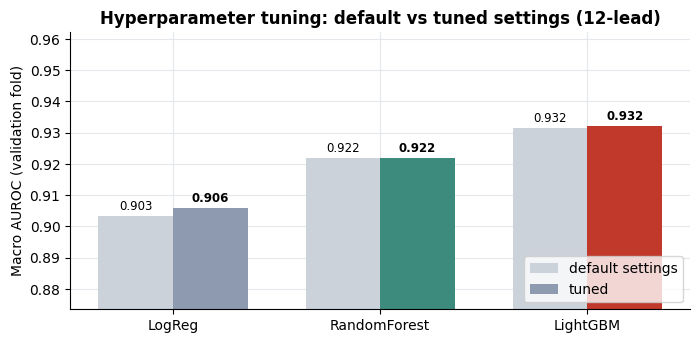

,default,tuned,gain
LogReg,0.9034,0.9058,0.0024
RandomForest,0.9219,0.9219,0.0000
LightGBM,0.9316,0.9322,0.0006


In [ ]:
# Default vs best tuned validation AUROC for each model
tuning_summary = pd.DataFrame({
    "default": {m: tuning[(tuning.model == m) & (tuning.candidate == "default")].val_macro_auroc.iloc[0]
                for m in MODEL_NAMES},
    "tuned": {m: tuning[tuning.model == m].val_macro_auroc.max() for m in MODEL_NAMES},
})
tuning_summary["gain"] = tuning_summary["tuned"] - tuning_summary["default"]

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(MODEL_NAMES))
ax.bar(x - 0.18, tuning_summary["default"], 0.36, color="#cbd2d9", label="default settings")
ax.bar(x + 0.18, tuning_summary["tuned"], 0.36, color=[MODEL_COLORS[m] for m in MODEL_NAMES], label="tuned")
for i, (d, t) in enumerate(zip(tuning_summary["default"], tuning_summary["tuned"])):
    ax.text(i - 0.18, d + 0.002, f"{d:.3f}", ha="center", fontsize=8.5)
    ax.text(i + 0.18, t + 0.002, f"{t:.3f}", ha="center", fontsize=8.5, fontweight="bold")
low = tuning_summary[["default", "tuned"]].values.min()
ax.set_ylim(max(0.5, low - 0.03), tuning_summary["tuned"].max() + 0.03)
ax.set_xticks(x, MODEL_NAMES); ax.set_ylabel("Macro AUROC (validation fold)")
ax.set_title("Hyperparameter tuning: default vs tuned settings (12-lead)", fontweight="bold")
ax.legend(loc="lower right")
save_figure(fig, "13_hyperparameter_tuning.png")

tuning_summary.round(4)

## 10. Train every model for every lead configuration and evaluate

**Metrics** (computed per class, then averaged over the 5 classes = *macro* average):

* **AUROC**: how well the model ranks sick above healthy ECGs (0.5 = random, 1 = perfect). Our main metric,
  because it does not depend on a threshold or on how common a class is.
* **AUPRC**: precision-recall area, informative for rare classes.
* **F1, sensitivity, specificity**: quality of the yes/no decisions at the tuned threshold.
* **Brier score and ECE** (Expected Calibration Error): how trustworthy the probabilities are (lower is better).
* **Retention**: reduced-lead AUROC as a % of the same model's 12-lead AUROC.
* **95% confidence intervals** from 500 bootstrap resamples of the test set.

In [ ]:
def expected_calibration_error(y, p, n_bins=10):
    """Average gap between predicted probability and observed frequency, over 10 bins."""
    bins = np.clip((p * n_bins).astype(int), 0, n_bins - 1)
    return float(sum((bins == b).mean() * abs(p[bins == b].mean() - y[bins == b].mean())
                     for b in range(n_bins) if (bins == b).any()))


def macro_auroc(Y, P):
    return float(np.mean([roc_auc_score(Y[:, k], P[:, k]) for k in range(len(CLASSES))]))


def evaluate(Y, P, P_raw, thresholds):
    """All metrics for one model on one test set. Y, P: arrays of shape (n_ECGs, 5)."""
    m = {}
    decisions = (P >= np.array([thresholds[c] for c in CLASSES])).astype(int)
    for k, c in enumerate(CLASSES):
        y, p = Y[:, k], P[:, k]
        decision = decisions[:, k]
        tp, fn = ((decision == 1) & (y == 1)).sum(), ((decision == 0) & (y == 1)).sum()
        tn, fp = ((decision == 0) & (y == 0)).sum(), ((decision == 1) & (y == 0)).sum()
        m[f"auroc_{c}"] = roc_auc_score(y, p)
        m[f"auprc_{c}"] = average_precision_score(y, p)
        m[f"f1_{c}"] = f1_score(y, decision, zero_division=0)
        m[f"sens_{c}"] = tp / (tp + fn) if tp + fn else np.nan
        m[f"spec_{c}"] = tn / (tn + fp) if tn + fp else np.nan
        m[f"acc_{c}"] = (tp + tn) / len(y)                              # share of correct yes/no decisions
        m[f"baseline_acc_{c}"] = max(y.mean(), 1 - y.mean())           # always predicting the majority answer
        m[f"brier_{c}"] = brier_score_loss(y, p)
        m[f"ece_{c}"] = expected_calibration_error(y, p)
        m[f"brier_uncal_{c}"] = brier_score_loss(y, P_raw[:, k])
        m[f"ece_uncal_{c}"] = expected_calibration_error(y, P_raw[:, k])
    for metric in ["auroc", "auprc", "f1", "sens", "spec", "acc", "baseline_acc", "brier", "ece",
                   "brier_uncal", "ece_uncal"]:
        m[f"macro_{metric}"] = float(np.nanmean([m[f"{metric}_{c}"] for c in CLASSES]))
    m["subset_accuracy"] = float((decisions == Y).all(axis=1).mean())   # all 5 labels exactly right
    return m



def bootstrap_ci(Y, P, n=N_BOOTSTRAP):
    """95% confidence interval of macro AUROC by resampling test ECGs with replacement."""
    rng = np.random.default_rng(RANDOM_STATE)
    scores = [macro_auroc(Y[i], P[i]) for i in (rng.integers(0, len(Y), len(Y)) for _ in range(n))]
    return float(np.percentile(scores, 2.5)), float(np.percentile(scores, 97.5))


X_train, X_val = X_all.loc[train_ids], X_all.loc[val_ids]
Y_train, Y_val = Y_all.loc[train_ids], Y_all.loc[val_ids]
Y_test = Y_all.loc[test_ids].values

rows, predictions, trained = [], {}, {}
for lead_set in LEAD_SET_NAMES:
    for model_name in MODEL_NAMES:
        t0 = time.time()
        model = ECGScreeningModel(model_name, lead_set).fit(X_train, Y_train, X_val, Y_val)
        trained[(model_name, lead_set)] = model

        # Evaluate on the test fold, clean and at every noise level
        for level in NOISE_LEVELS:
            X_test = features[level].loc[test_ids]
            P, P_raw = model.predict_proba(X_test), model.predict_proba(X_test, calibrated=False)
            predictions[(model_name, lead_set, str(level))] = {"P": P, "P_raw": P_raw}
            row = {"model": model_name, "lead_set": lead_set, "noise": str(level),
                   **evaluate(Y_test, P, P_raw, model.thresholds)}
            if level == "clean":
                row["auroc_ci_lo"], row["auroc_ci_hi"] = bootstrap_ci(Y_test, P)
            rows.append(row)

        clean = rows[-len(NOISE_LEVELS)]
        print(f"{model_name:12s} {lead_set:8s} AUROC {clean['macro_auroc']:.3f} "
              f"[{clean['auroc_ci_lo']:.3f}-{clean['auroc_ci_hi']:.3f}]  F1 {clean['macro_f1']:.3f}  "
              f"ECE {clean['macro_ece']:.3f}   ({time.time() - t0:.0f}s)")

metrics = pd.DataFrame(rows)
# Retention = AUROC as % of the same model's clean 12-lead AUROC
reference = metrics[(metrics.lead_set == "12-lead") & (metrics.noise == "clean")].set_index("model")["macro_auroc"]
metrics["retention_pct"] = 100 * metrics["macro_auroc"] / metrics["model"].map(reference)
metrics.to_csv(RESULTS_DIR / "metrics.csv", index=False)

clean_metrics = metrics[metrics.noise == "clean"]
BEST_MODEL = clean_metrics.groupby("model")["macro_auroc"].mean().idxmax()
print(f"\nBest model overall: {BEST_MODEL}")

LogReg       12-lead  AUROC 0.897 [0.889-0.905]  F1 0.697  ECE 0.018   (18s)
RandomForest 12-lead  AUROC 0.910 [0.903-0.917]  F1 0.718  ECE 0.019   (84s)
LightGBM     12-lead  AUROC 0.924 [0.917-0.931]  F1 0.742  ECE 0.017   (34s)
LogReg       6-lead   AUROC 0.868 [0.859-0.877]  F1 0.660  ECE 0.018   (17s)
RandomForest 6-lead   AUROC 0.883 [0.873-0.892]  F1 0.676  ECE 0.019   (72s)
LightGBM     6-lead   AUROC 0.892 [0.882-0.899]  F1 0.688  ECE 0.018   (27s)
LogReg       3-lead   AUROC 0.872 [0.862-0.880]  F1 0.654  ECE 0.023   (12s)
RandomForest 3-lead   AUROC 0.887 [0.879-0.896]  F1 0.680  ECE 0.020   (63s)
LightGBM     3-lead   AUROC 0.901 [0.893-0.908]  F1 0.691  ECE 0.021   (22s)
LogReg       1-lead   AUROC 0.812 [0.800-0.822]  F1 0.592  ECE 0.018   (11s)
RandomForest 1-lead   AUROC 0.824 [0.812-0.835]  F1 0.605  ECE 0.020   (54s)
LightGBM     1-lead   AUROC 0.828 [0.817-0.839]  F1 0.614  ECE 0.016   (16s)

Best model overall: LightGBM


### 10.1 Results table (test fold, clean signals)

In [ ]:
results_table = clean_metrics.pivot(index="model", columns="lead_set", values="macro_auroc")[LEAD_SET_NAMES]
retention_table = clean_metrics.pivot(index="model", columns="lead_set", values="retention_pct")[LEAD_SET_NAMES]
print("Macro AUROC:"); display(results_table.loc[MODEL_NAMES].round(3))
print("Retention (% of 12-lead AUROC):"); display(retention_table.loc[MODEL_NAMES].round(1))

Macro AUROC:


lead_set,12-lead,6-lead,3-lead,1-lead
model,,,,
LogReg,0.897,0.868,0.872,0.812
RandomForest,0.910,0.883,0.887,0.824
LightGBM,0.924,0.892,0.901,0.828


Retention (% of 12-lead AUROC):


lead_set,12-lead,6-lead,3-lead,1-lead
model,,,,
LogReg,100.0,96.8,97.3,90.5
RandomForest,100.0,97.0,97.5,90.5
LightGBM,100.0,96.5,97.5,89.7


### 10.1b Accuracy, and why it is not the main metric

Accuracy = share of correct yes/no decisions. The **majority baseline** is the accuracy of a "model" that always
gives the most common answer (e.g. always "no hypertrophy"). Because only ~12% of ECGs have HYP, that useless
baseline already scores ~88%. This is why we rank models with **AUROC**, which a do-nothing model cannot inflate,
and report accuracy only alongside its baseline. **Subset accuracy** is the strictest score: all five labels of an
ECG must be exactly right.

In [ ]:
best = clean_metrics[clean_metrics.model == BEST_MODEL].set_index("lead_set")
accuracy_table = pd.DataFrame({
    "majority baseline": [best.loc["12-lead", f"baseline_acc_{c}"] for c in CLASSES],
    **{f"{BEST_MODEL} {ls}": [best.loc[ls, f"acc_{c}"] for c in CLASSES] for ls in LEAD_SET_NAMES},
}, index=[f"{c} - {CLASS_NAMES[c]}" for c in CLASSES])
accuracy_table.loc["Macro average"] = accuracy_table.mean()
display((accuracy_table * 100).round(1).astype(str) + "%")

print("Subset accuracy (all 5 labels exactly right):",
      ", ".join(f"{ls} {best.loc[ls, 'subset_accuracy']:.1%}" for ls in LEAD_SET_NAMES))

,majority baseline,LightGBM 12-lead,LightGBM 6-lead,LightGBM 3-lead,LightGBM 1-lead
NORM - Normal ECG,55.4%,85.8%,85.2%,84.1%,80.3%
MI - Myocardial infarction,74.5%,85.8%,82.3%,83.1%,72.7%
STTC - ST/T change,75.9%,88.5%,84.8%,86.1%,83.1%
CD - Conduction disturbance,77.0%,89.1%,85.8%,87.8%,82.1%
HYP - Hypertrophy,87.9%,90.7%,86.9%,86.6%,81.8%
Macro average,74.1%,88.0%,85.0%,85.5%,80.0%


Subset accuracy (all 5 labels exactly right): 12-lead 59.9%, 6-lead 51.4%, 3-lead 53.9%, 1-lead 43.7%


### 10.2 Is the loss statistically significant? (paired bootstrap)

We resample the **same** test patients for the 12-lead and the reduced-lead model, compute the AUROC difference
500 times, and read off a 95% confidence interval. If the interval does not include 0, the loss is significant.

In [ ]:
paired_rows = []
for model_name in MODEL_NAMES:
    P_full = predictions[(model_name, "12-lead", "clean")]["P"]
    for lead_set in LEAD_SET_NAMES[1:]:
        P_reduced = predictions[(model_name, lead_set, "clean")]["P"]
        rng = np.random.default_rng(RANDOM_STATE)
        diffs = []
        for _ in range(N_BOOTSTRAP):
            i = rng.integers(0, len(Y_test), len(Y_test))
            diffs.append(macro_auroc(Y_test[i], P_reduced[i]) - macro_auroc(Y_test[i], P_full[i]))
        diffs = np.array(diffs)
        paired_rows.append({"model": model_name, "lead_set": lead_set,
                            "diff": macro_auroc(Y_test, P_reduced) - macro_auroc(Y_test, P_full),
                            "lo": np.percentile(diffs, 2.5), "hi": np.percentile(diffs, 97.5),
                            "p_value": min(1.0, 2 * min((diffs >= 0).mean(), (diffs <= 0).mean()))})
paired = pd.DataFrame(paired_rows)
paired["significant loss"] = paired["hi"] < 0
paired.to_csv(RESULTS_DIR / "paired_bootstrap_vs_12lead.csv", index=False)
paired.round(3)

,model,lead_set,diff,lo,hi,p_value,significant loss
0,LogReg,6-lead,-0.028,-0.034,-0.023,0.0,True
1,LogReg,3-lead,-0.025,-0.030,-0.019,0.0,True
2,LogReg,1-lead,-0.085,-0.095,-0.075,0.0,True
3,RandomForest,6-lead,-0.027,-0.033,-0.022,0.0,True
4,RandomForest,3-lead,-0.023,-0.028,-0.018,0.0,True
5,RandomForest,1-lead,-0.086,-0.095,-0.077,0.0,True
6,LightGBM,6-lead,-0.032,-0.038,-0.028,0.0,True
7,LightGBM,3-lead,-0.023,-0.028,-0.019,0.0,True
8,LightGBM,1-lead,-0.096,-0.106,-0.086,0.0,True


### 10.3 Figures: discrimination and retention

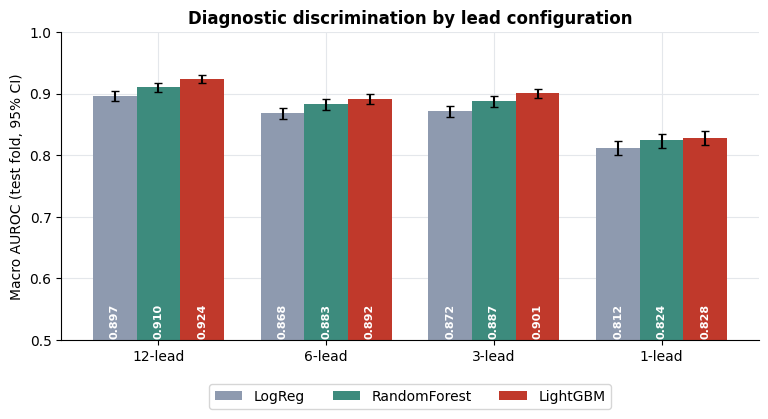

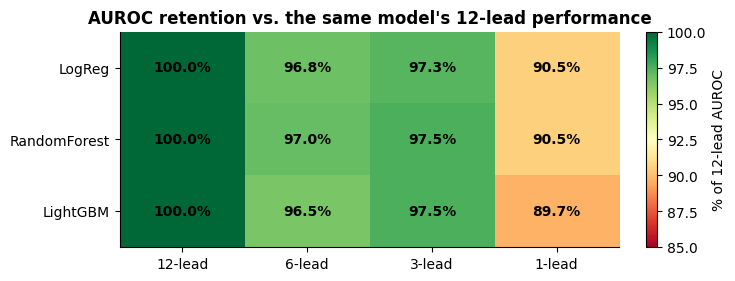

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
x, width = np.arange(len(LEAD_SET_NAMES)), 0.26
for i, model_name in enumerate(MODEL_NAMES):
    d = clean_metrics[clean_metrics.model == model_name].set_index("lead_set").loc[LEAD_SET_NAMES]
    errors = [d.macro_auroc - d.auroc_ci_lo, d.auroc_ci_hi - d.macro_auroc]
    bars = ax.bar(x + (i - 1) * width, d.macro_auroc, width, yerr=errors, capsize=3,
                  color=MODEL_COLORS[model_name], label=model_name)
    for bar, value in zip(bars, d.macro_auroc):
        ax.text(bar.get_x() + bar.get_width() / 2, 0.502, f"{value:.3f}", ha="center", va="bottom",
                rotation=90, color="white", fontsize=8, fontweight="bold")
ax.set_xticks(x, LEAD_SET_NAMES); ax.set_ylim(0.5, 1.0)
ax.set_ylabel("Macro AUROC (test fold, 95% CI)")
ax.set_title("Diagnostic discrimination by lead configuration", fontweight="bold")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
save_figure(fig, "04_auroc_by_leadset.png")

fig, ax = plt.subplots(figsize=(7, 2.8))
values = retention_table.loc[MODEL_NAMES].values
image = ax.imshow(values, cmap="RdYlGn", vmin=min(85, values.min()), vmax=100, aspect="auto")
ax.set_xticks(range(4), LEAD_SET_NAMES); ax.set_yticks(range(3), MODEL_NAMES); ax.grid(False)
for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        ax.text(j, i, f"{values[i, j]:.1f}%", ha="center", va="center", fontweight="bold")
ax.set_title("AUROC retention vs. the same model's 12-lead performance", fontweight="bold")
fig.colorbar(image, ax=ax, fraction=0.03, label="% of 12-lead AUROC")
save_figure(fig, "05_retention_heatmap.png")

### 10.4 Which conditions survive lead reduction?

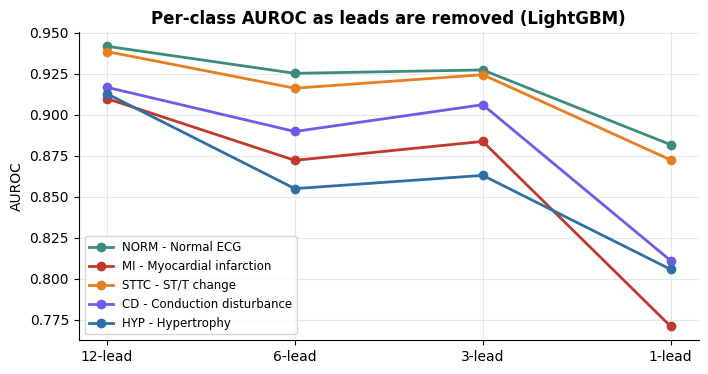

lead_set,12-lead,6-lead,3-lead,1-lead
auroc_NORM,0.942,0.925,0.927,0.882
auroc_MI,0.910,0.872,0.884,0.771
auroc_STTC,0.939,0.916,0.924,0.872
auroc_CD,0.917,0.890,0.906,0.811
auroc_HYP,0.913,0.855,0.863,0.806


In [ ]:
per_class = clean_metrics[clean_metrics.model == BEST_MODEL].set_index("lead_set").loc[LEAD_SET_NAMES]
fig, ax = plt.subplots(figsize=(8, 4))
for c in CLASSES:
    ax.plot(LEAD_SET_NAMES, per_class[f"auroc_{c}"], marker="o", lw=2, color=CLASS_COLORS[c],
            label=f"{c} - {CLASS_NAMES[c]}")
ax.set_ylabel("AUROC"); ax.legend(fontsize=8.5, loc="lower left")
ax.set_title(f"Per-class AUROC as leads are removed ({BEST_MODEL})", fontweight="bold")
save_figure(fig, "06_per_class_auroc.png")

per_class[[f"auroc_{c}" for c in CLASSES]].T.round(3)

### 10.5 ROC curves, calibration and confusion matrices

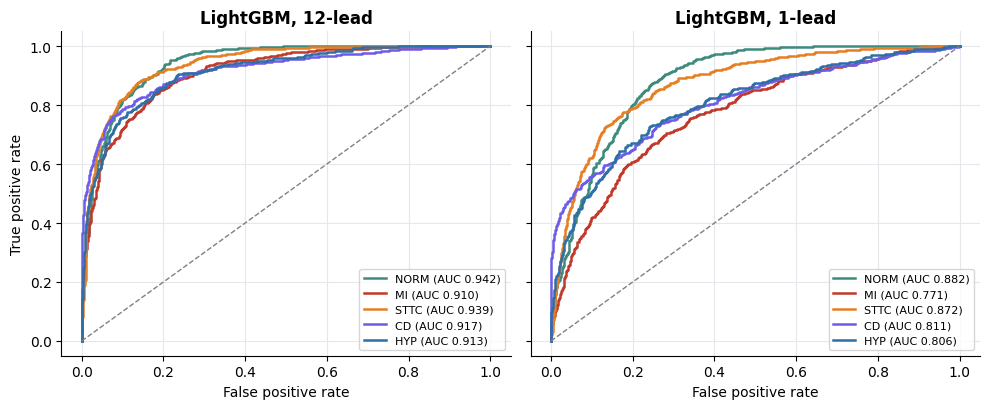

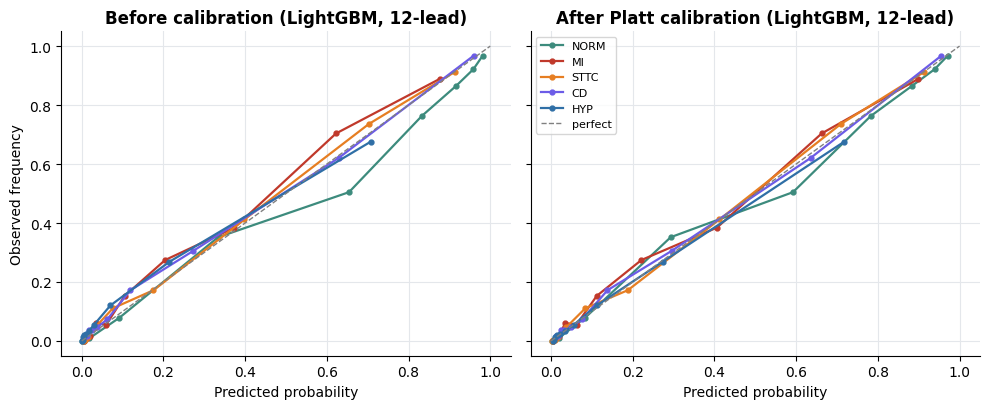

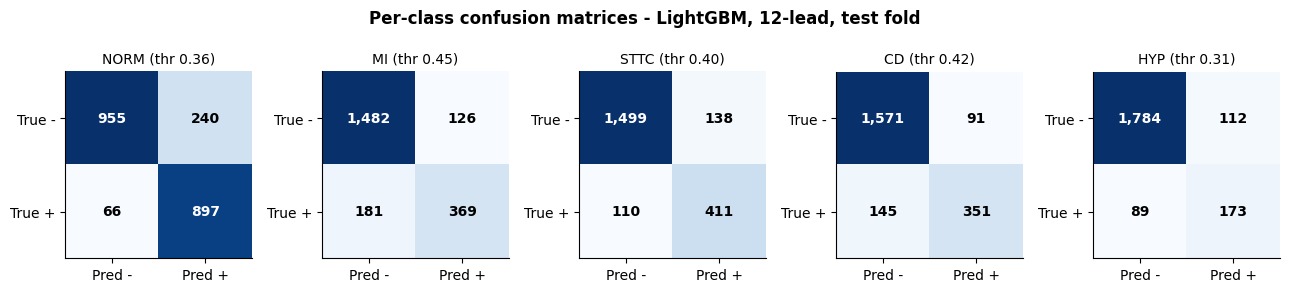

ECE before calibration: 0.027 | after: 0.0166


In [ ]:
# ROC curves: 12 leads vs 1 lead
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, lead_set in zip(axes, ["12-lead", "1-lead"]):
    P = predictions[(BEST_MODEL, lead_set, "clean")]["P"]
    for k, c in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(Y_test[:, k], P[:, k])
        ax.plot(fpr, tpr, color=CLASS_COLORS[c], lw=1.8, label=f"{c} (AUC {roc_auc_score(Y_test[:, k], P[:, k]):.3f})")
    ax.plot([0, 1], [0, 1], "--", color="grey", lw=1)
    ax.set_title(f"{BEST_MODEL}, {lead_set}", fontweight="bold"); ax.set_xlabel("False positive rate")
    ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("True positive rate")
fig.tight_layout()
save_figure(fig, "08_roc_curves.png")

# Calibration: before vs after Platt scaling
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, key, title in [(axes[0], "P_raw", "Before calibration"), (axes[1], "P", "After Platt calibration")]:
    for k, c in enumerate(CLASSES):
        observed, predicted = calibration_curve(Y_test[:, k], predictions[(BEST_MODEL, "12-lead", "clean")][key][:, k],
                                                n_bins=10, strategy="quantile")
        ax.plot(predicted, observed, marker="o", ms=3.5, lw=1.6, color=CLASS_COLORS[c], label=c)
    ax.plot([0, 1], [0, 1], "--", color="grey", lw=1, label="perfect")
    ax.set_title(f"{title} ({BEST_MODEL}, 12-lead)", fontweight="bold"); ax.set_xlabel("Predicted probability")
axes[0].set_ylabel("Observed frequency"); axes[1].legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "09_calibration.png")

# Confusion matrix for each class at its tuned threshold
best_12 = trained[(BEST_MODEL, "12-lead")]
P = predictions[(BEST_MODEL, "12-lead", "clean")]["P"]
fig, axes = plt.subplots(1, 5, figsize=(13, 2.9))
for k, (ax, c) in enumerate(zip(axes, CLASSES)):
    decision = (P[:, k] >= best_12.thresholds[c]).astype(int)
    matrix = np.array([[((Y_test[:, k] == a) & (decision == b)).sum() for b in (0, 1)] for a in (0, 1)])
    ax.imshow(matrix, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matrix[i, j]:,}", ha="center", va="center", fontweight="bold",
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Pred -", "Pred +"]); ax.set_yticks([0, 1], ["True -", "True +"])
    ax.set_title(f"{c} (thr {best_12.thresholds[c]:.2f})", fontsize=10)
fig.suptitle(f"Per-class confusion matrices - {BEST_MODEL}, 12-lead, test fold", fontweight="bold")
fig.tight_layout()
save_figure(fig, "10_confusion_matrices.png")

print("ECE before calibration:", round(clean_metrics.set_index(["model", "lead_set"]).loc[(BEST_MODEL, "12-lead"), "macro_ece_uncal"], 4),
      "| after:", round(clean_metrics.set_index(["model", "lead_set"]).loc[(BEST_MODEL, "12-lead"), "macro_ece"], 4))

## 11. Robustness to wearable noise

All models were trained on clean ECGs. Here they are tested on the same test ECGs with noise added.

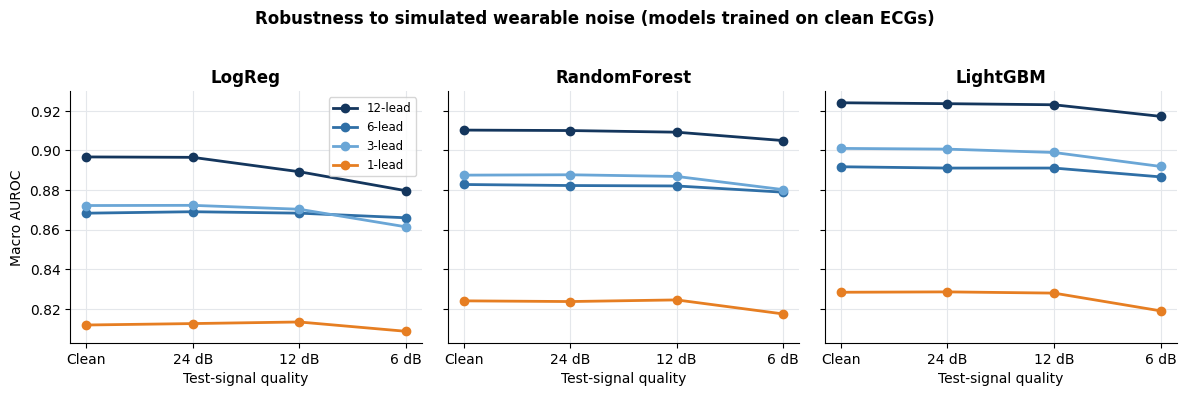

noise,clean,24,12,6
lead_set,,,,
12-lead,0.924,0.924,0.923,0.917
6-lead,0.892,0.891,0.891,0.887
3-lead,0.901,0.901,0.899,0.892
1-lead,0.828,0.829,0.828,0.819


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
labels = ["Clean" if n == "clean" else f"{n} dB" for n in NOISE_LEVELS]
for ax, model_name in zip(axes, MODEL_NAMES):
    for lead_set in LEAD_SET_NAMES:
        d = metrics[(metrics.model == model_name) & (metrics.lead_set == lead_set)].set_index("noise")
        ax.plot(labels, d.loc[[str(n) for n in NOISE_LEVELS], "macro_auroc"], marker="o", lw=2,
                color=LEADSET_COLORS[lead_set], label=lead_set)
    ax.set_title(model_name, fontweight="bold"); ax.set_xlabel("Test-signal quality")
axes[0].set_ylabel("Macro AUROC"); axes[0].legend(fontsize=8.5)
fig.suptitle("Robustness to simulated wearable noise (models trained on clean ECGs)", fontweight="bold", y=1.03)
fig.tight_layout()
save_figure(fig, "07_noise_robustness.png")

metrics[metrics.model == BEST_MODEL].pivot(index="lead_set", columns="noise", values="macro_auroc") \
    .loc[LEAD_SET_NAMES, [str(n) for n in NOISE_LEVELS]].round(3)

## 12. Explainability with SHAP

**SHAP** splits each prediction into contributions from each feature (in log-odds). Averaging the absolute
contributions over many ECGs shows which features, and therefore which **leads**, the model relies on.
We use the LightGBM models because TreeSHAP computes exact values for tree models quickly.

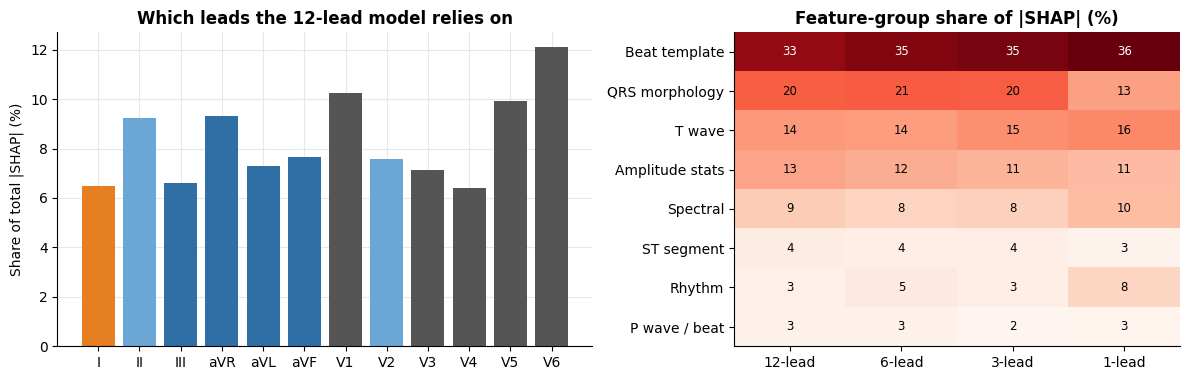

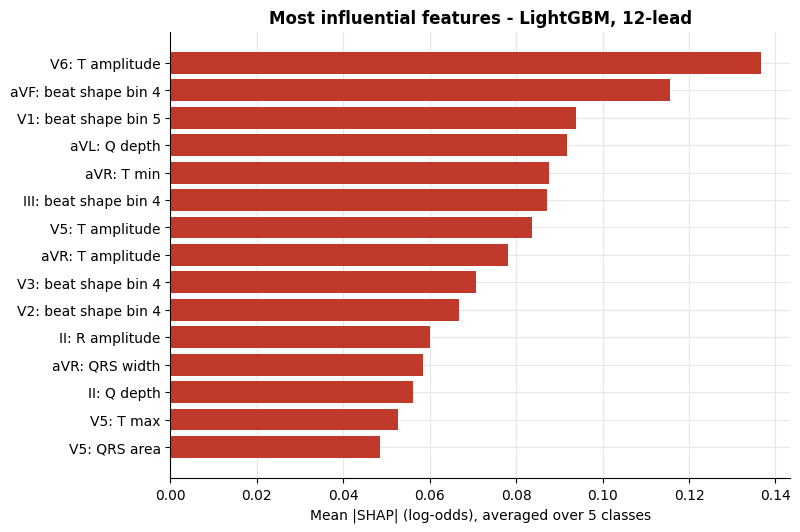

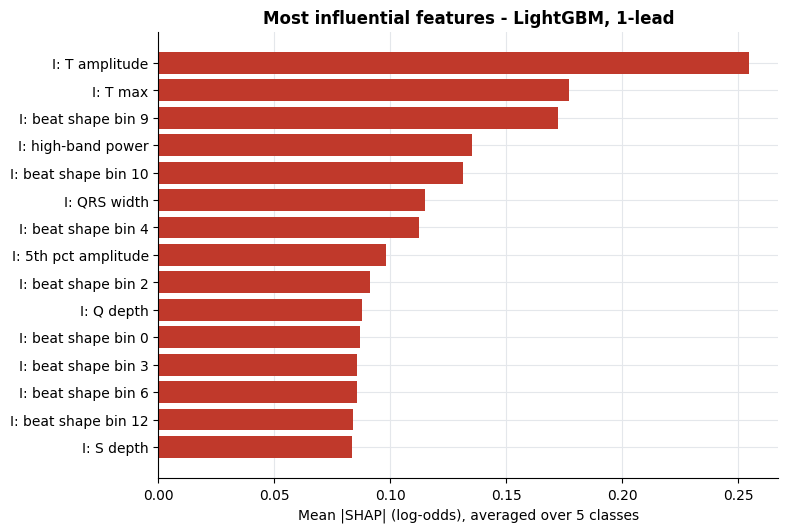

In [ ]:
import shap

FEATURE_GROUPS = {
    "Rhythm": ["n_beats", "hr", "rr_std", "rr_cv", "rmssd", "pnn50", "rr_range"],
    "Amplitude stats": ["std", "ptp", "skew", "kurt", "p05", "p95", "abs_mean", "zcr"],
    "Spectral": ["bp_low", "bp_mid", "bp_high", "spec_entropy", "peak_freq"],
    "QRS morphology": ["q_amp", "r_amp", "s_amp", "qrs_ptp", "qrs_area", "qrs_width"],
    "ST segment": ["st_level", "st_slope"],
    "T wave": ["t_amp", "t_max", "t_min", "t_area"],
    "P wave / beat": ["p_amp", "beat_corr"],
    "Beat template": [f"tmpl_{i}" for i in range(14)],
}
GROUP_OF = {feature: group for group, names in FEATURE_GROUPS.items() for feature in names}
from src.app_model import pretty           # readable names, e.g. "V2__st_level" -> "V2: ST level"

shap_importance = {}
X_explain = X_all.loc[test_ids].sample(min(1000, len(test_ids)), random_state=RANDOM_STATE)
for lead_set in LEAD_SET_NAMES:
    model = trained[("LightGBM", lead_set)]
    per_class = {}
    for c in CLASSES:
        values = shap.TreeExplainer(model.models[c]).shap_values(X_explain[model.columns])
        values = values[1] if isinstance(values, list) else values         # older shap versions return a list
        per_class[c] = np.abs(values).mean(axis=0)
    table = pd.DataFrame(per_class, index=model.columns)
    table["mean"] = table[CLASSES].mean(axis=1)
    shap_importance[lead_set] = table.sort_values("mean", ascending=False)
    shap_importance[lead_set].to_csv(RESULTS_DIR / f"shap_importance_{lead_set}.csv")

# Share of attribution per lead (12-lead model) and per feature group (every configuration)
imp12 = shap_importance["12-lead"]["mean"]
lead_share = imp12.groupby(lambda col: col.split("__")[0]).sum()
lead_share = (lead_share / lead_share.sum()).reindex(ALL_LEADS)
group_share = {ls: (lambda s: s / s.sum())(shap_importance[ls]["mean"].groupby(lambda col: GROUP_OF[col.split("__")[1]]).sum())
               for ls in LEAD_SET_NAMES}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1.2, 1]})
ax1.bar([l.replace("AV", "aV") for l in ALL_LEADS], lead_share.values * 100,
        color=[LEADSET_COLORS[smallest_set_with(l)] if smallest_set_with(l) != "12-lead" else "#555" for l in ALL_LEADS])
ax1.set_ylabel("Share of total |SHAP| (%)"); ax1.set_title("Which leads the 12-lead model relies on", fontweight="bold")
groups = group_share["12-lead"].sort_values(ascending=False).index
matrix = pd.DataFrame(group_share).reindex(groups)[LEAD_SET_NAMES] * 100
ax2.imshow(matrix.values, cmap="Reds", aspect="auto"); ax2.grid(False)
ax2.set_xticks(range(4), LEAD_SET_NAMES); ax2.set_yticks(range(len(groups)), groups)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax2.text(j, i, f"{matrix.values[i, j]:.0f}", ha="center", va="center", fontsize=8.5,
                 color="white" if matrix.values[i, j] > matrix.values.max() * 0.6 else "black")
ax2.set_title("Feature-group share of |SHAP| (%)", fontweight="bold")
fig.tight_layout()
save_figure(fig, "12_shap_leads_groups.png")

for lead_set, tag in [("12-lead", "12lead"), ("1-lead", "1lead")]:
    top = shap_importance[lead_set].head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 5.8))
    ax.barh([pretty(col) for col in top.index], top["mean"], color="#c0392b")
    ax.set_xlabel("Mean |SHAP| (log-odds), averaged over 5 classes")
    ax.set_title(f"Most influential features - LightGBM, {lead_set}", fontweight="bold")
    save_figure(fig, f"11_shap_top_{tag}.png")

## 13. Save everything for the app, report and slides

**Models for the Streamlit app.** Pickle files break when library versions differ between your laptop and
Streamlit Cloud, so each LightGBM model is saved as plain JSON: the tree model in LightGBM's own text format,
the two Platt-calibration numbers, and the threshold.

In [ ]:
def export_for_app(model, path):
    """Save a calibrated LightGBM ECGScreeningModel as JSON for the Streamlit app."""
    data = {"lead_set": model.lead_set, "leads": LEAD_SETS[model.lead_set],
            "feature_columns": model.columns, "classes": CLASSES, "per_class": {}}
    for c in CLASSES:
        data["per_class"][c] = {"booster": model.models[c].booster_.model_to_string(),
                                "platt_a": float(model.calibrators[c].coef_[0][0]),
                                "platt_b": float(model.calibrators[c].intercept_[0]),
                                "threshold": model.thresholds[c]}
    Path(path).write_text(json.dumps(data))


for lead_set in LEAD_SET_NAMES:
    export_for_app(trained[(APP_MODEL, lead_set)], MODEL_DIR / f"{lead_set}.json")

# Check: the app's loader reproduces the notebook's probabilities exactly
from src.app_model import AppModel
app_model = AppModel(MODEL_DIR / "12-lead.json")
one_ecg = X_all.loc[test_ids[:1]]
assert np.allclose(trained[(APP_MODEL, "12-lead")].predict_proba(one_ecg)[0],
                   list(app_model.predict_proba(one_ecg).values()), atol=1e-6)
print("✓ Models saved to models/ and verified with the app's loader.")

# Example ECGs for the app: 3 single-label test ECGs per class + 3 multi-label ones
for old in SAMPLE_DIR.glob("*.npz"):
    old.unlink()
test_meta = meta.loc[test_ids]
single = test_meta[test_meta[CLASSES].sum(axis=1) == 1]
chosen = [i for c in CLASSES for i in single[single[c] == 1].index[:3]]
chosen += list(test_meta[test_meta[CLASSES].sum(axis=1) > 1].index[:3])
for ecg_id in chosen:
    row = test_meta.loc[ecg_id]
    np.savez_compressed(SAMPLE_DIR / f"ecg_{ecg_id:05d}.npz", signal=read_ecg(row.filename_lr),
                        labels=np.array([row[c] for c in CLASSES]), ecg_id=int(ecg_id),
                        age=float(row.age) if pd.notna(row.age) else np.nan, sex=int(row.sex) if pd.notna(row.sex) else -1)
first = read_ecg(test_meta.loc[chosen[0], "filename_lr"])
pd.DataFrame(first, columns=ALL_LEADS).round(4).to_csv(SAMPLE_DIR / "example_upload_12lead.csv", index=False)
pd.DataFrame(first[:, [0]], columns=["I"]).round(4).to_csv(SAMPLE_DIR / "example_upload_watch_leadI.csv", index=False)
print(f"✓ {len(chosen)} example ECGs saved to app_samples/.")

✓ Models saved to models/ and verified with the app's loader.
✓ 18 example ECGs saved to app_samples/.


### Pipeline diagram (used in the report and slides)

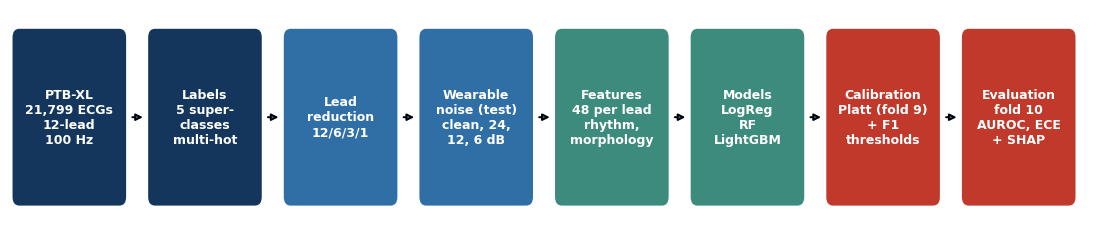

In [ ]:
from matplotlib.patches import FancyBboxPatch

steps = [("PTB-XL\n21,799 ECGs\n12-lead\n100 Hz", "#14365d"), ("Labels\n5 super-\nclasses\nmulti-hot", "#14365d"),
         ("Lead\nreduction\n12/6/3/1", "#2f6fa6"), ("Wearable\nnoise (test)\nclean, 24,\n12, 6 dB", "#2f6fa6"),
         ("Features\n48 per lead\nrhythm,\nmorphology", "#3d8b7d"), ("Models\nLogReg\nRF\nLightGBM", "#3d8b7d"),
         ("Calibration\nPlatt (fold 9)\n+ F1\nthresholds", "#c0392b"), ("Evaluation\nfold 10\nAUROC, ECE\n+ SHAP", "#c0392b")]
fig, ax = plt.subplots(figsize=(14, 2.8))
ax.set_xlim(0, len(steps) * 1.6); ax.set_ylim(0, 2); ax.axis("off")
for i, (text, colour) in enumerate(steps):
    x = i * 1.6 + 0.05
    ax.add_patch(FancyBboxPatch((x, 0.2), 1.3, 1.6, boxstyle="round,pad=0.02,rounding_size=0.08", fc=colour, ec="none"))
    ax.text(x + 0.65, 1.0, text, ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    if i < len(steps) - 1:
        ax.annotate("", xy=(x + 1.55, 1.0), xytext=(x + 1.36, 1.0), arrowprops=dict(arrowstyle="-|>", lw=1.4))
save_figure(fig, "00_pipeline.png")

### Summary file
`results/summary.json` collects every headline number. The report and slide generators read only this file,
so every number in them comes from this run.

In [ ]:
def value(model, lead_set, column="macro_auroc", noise="clean"):
    row = metrics[(metrics.model == model) & (metrics.lead_set == lead_set) & (metrics.noise == str(noise))]
    return float(row[column].iloc[0])


def table(column):
    return {m: {ls: value(m, ls, column) for ls in LEAD_SET_NAMES} for m in MODEL_NAMES}


summary = {
    "generated": time.strftime("%Y-%m-%d %H:%M"),
    "runtime_min": round((time.time() - START_TIME) / 60, 1),
    "fast_mode": FAST_MODE, "best_model": BEST_MODEL, "app_model": APP_MODEL,
    "lead_sets": LEAD_SETS, "noise_levels": [str(n) for n in NOISE_LEVELS],
    "dataset": {
        "n_records_raw": n_records_raw, "n_records_used": len(meta), "n_dropped_no_label": n_dropped,
        "n_patients": int(meta["patient_id"].nunique()), "sampling_rate_hz": FS, "seconds": 10, "n_leads": 12,
        "age_mean": float(meta["age"].replace(300, np.nan).mean()), "age_std": float(meta["age"].replace(300, np.nan).std()),
        "pct_male": float((meta["sex"] == 0).mean() * 100),
        "metadata_missing_pct": {c: float(meta[c].isna().mean() * 100) for c in ["age", "sex", "height", "weight"]},
        "class_counts": {c: int(meta[c].sum()) for c in CLASSES},
        "class_pct": {c: float(meta[c].mean() * 100) for c in CLASSES},
        "multilabel_pct": float((meta[CLASSES].sum(axis=1) > 1).mean() * 100),
        "split_sizes": {"train": len(train_ids), "val": len(val_ids), "test": len(test_ids)},
        "split_class_pct": {name: {c: float(meta.loc[ids, c].mean() * 100) for c in CLASSES}
                            for name, ids in [("train", train_ids), ("val", val_ids), ("test", test_ids)]},
        "features_per_lead": FEATURES_PER_LEAD,
        "n_features_by_leadset": {ls: len(columns_for(ls)) for ls in LEAD_SET_NAMES},
        "feature_missing_pct": float(missing_share.mean() * 100),
        "feature_missing_max_pct": float(missing_share.max() * 100),
        "synthetic": IS_SYNTHETIC,
    },
    "macro_auroc": table("macro_auroc"), "macro_f1": table("macro_f1"), "macro_auprc": table("macro_auprc"),
    "retention_pct": table("retention_pct"),
    "auroc_ci": {m: {ls: [value(m, ls, "auroc_ci_lo"), value(m, ls, "auroc_ci_hi")] for ls in LEAD_SET_NAMES} for m in MODEL_NAMES},
    "ece": {m: {ls: {"calibrated": value(m, ls, "macro_ece"), "uncalibrated": value(m, ls, "macro_ece_uncal")}
                for ls in LEAD_SET_NAMES} for m in MODEL_NAMES},
    "brier": {m: {ls: {"calibrated": value(m, ls, "macro_brier"), "uncalibrated": value(m, ls, "macro_brier_uncal")}
                  for ls in LEAD_SET_NAMES} for m in MODEL_NAMES},
    "noise_auroc": {m: {ls: {str(n): value(m, ls, noise=n) for n in NOISE_LEVELS} for ls in LEAD_SET_NAMES} for m in MODEL_NAMES},
    "per_class_auroc": {m: {ls: {c: value(m, ls, f"auroc_{c}") for c in CLASSES} for ls in LEAD_SET_NAMES} for m in MODEL_NAMES},
    "per_class_best_12": {c: {k: value(BEST_MODEL, "12-lead", f"{k}_{c}") for k in ["auroc", "auprc", "f1", "sens", "spec"]}
                          for c in CLASSES},
    "thresholds_best_12": trained[(BEST_MODEL, "12-lead")].thresholds,
    "paired_vs_12": paired.drop(columns="significant loss").to_dict(orient="records"),
    "shap_lead_importance_12": {k: float(v) for k, v in lead_share.items()},
    "shap_group_importance": {ls: {k: float(v) for k, v in s.items()} for ls, s in group_share.items()},
    "shap_top_12": [{"feature": f, "importance": float(v)} for f, v in shap_importance["12-lead"]["mean"].head(10).items()],
    "shap_top_1": [{"feature": f, "importance": float(v)} for f, v in shap_importance["1-lead"]["mean"].head(10).items()],
    "app_samples": [int(i) for i in chosen],
}
(RESULTS_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
(MODEL_DIR / "manifest.json").write_text(json.dumps({"model": APP_MODEL, "classes": CLASSES,
                                                     "lead_sets": LEAD_SETS, "synthetic": IS_SYNTHETIC}, indent=2))
print(f"✓ Summary saved. Total runtime: {summary['runtime_min']} min")

✓ Summary saved. Total runtime: 18.8 min


In [ ]:
# Add the tuning and accuracy results to summary.json so the report and slides can describe them
def plain(v):
    """Convert numpy numbers to plain Python numbers so they can be saved as JSON."""
    return v if isinstance(v, str) else (int(v) if float(v).is_integer() and not isinstance(v, float) else float(v))


summary["tuned_params"] = {m: {k: plain(v) for k, v in TUNED_PARAMS[m].items()} for m in MODEL_NAMES}
summary["tuning_val_auroc"] = {m: {"default": float(tuning_summary.loc[m, "default"]),
                                   "tuned": float(tuning_summary.loc[m, "tuned"])} for m in MODEL_NAMES}

# Accuracy (only if the accuracy columns were computed in section 10)
if "acc_NORM" in metrics.columns:
    for c in CLASSES:
        summary["per_class_best_12"][c]["acc"] = value(BEST_MODEL, "12-lead", f"acc_{c}")
        summary["per_class_best_12"][c]["baseline_acc"] = value(BEST_MODEL, "12-lead", f"baseline_acc_{c}")
    summary["subset_accuracy"] = {ls: value(BEST_MODEL, ls, "subset_accuracy") for ls in LEAD_SET_NAMES}

(RESULTS_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
print("✓ Tuning (and accuracy) results added to summary.json")

✓ Tuning (and accuracy) results added to summary.json


## 14. Generate the report and the slides

Edit your name, PRN and guide below, then run the cell. The files appear in `reports/`.
(After deploying, add your GitHub and Streamlit links with `--repo` and `--app`.)

In [ ]:
import subprocess
import sys

AUTHOR, PRN, GUIDE = "Kashish Chelwani", "", ""

for script in ["scripts/make_report.py", "scripts/make_slides.py"]:
    output = subprocess.run([sys.executable, script, "--author", AUTHOR, "--prn", PRN, "--guide", GUIDE],
                            capture_output=True, text=True)
    print(output.stdout or output.stderr)

c:\Users\Kashish\anaconda3\python.exe: can't open file 'c:\\Users\\Kashish\\Downloads\\lowlead-ecg-screening\\lowlead-ecg-screening\\scripts\\make_report.py': [Errno 2] No such file or directory

c:\Users\Kashish\anaconda3\python.exe: can't open file 'c:\\Users\\Kashish\\Downloads\\lowlead-ecg-screening\\lowlead-ecg-screening\\scripts\\make_slides.py': [Errno 2] No such file or directory

